# Project UAS Tema 1 Bansos

*   Crawling Data + Text Preprocessing +
Klasifikasi/Sentiment - Mahasiswa A
*   Klasterisasi + Deteksi
Trending Topic - Mahasiswa B
* Social Network
Analysis (SNA) + Pembuatan Dashboard Panel (bisa pakai Streamlit
Python, Looker Studio, atau Tableau) - Mahasiswa C



# 1. Crawling Data + Text Preprocessing + Klasifikasi/Sentiment

In [1]:
import pandas as pd
df = pd.read_csv('/content/bansos.csv')# ganti nama kolom teks kalau beda
print(df.head())
print(df.info()) #Struktur data
print("Jumlah data:", len(df))


   conversation_id_str                      created_at  favorite_count  \
0  2039047860503933054  Tue Mar 31 23:52:16 +0000 2026              25   
1  2039026185112314153  Tue Mar 31 17:05:00 +0000 2026               0   
2  2038920133759181118  Tue Mar 31 15:17:31 +0000 2026               5   
3  2038966467001991403  Tue Mar 31 14:57:30 +0000 2026               2   
4  2038991280072769922  Tue Mar 31 14:46:18 +0000 2026               1   

                                           full_text               id_str  \
0  @Xbacottetangga Tdk kuasa kutahan airmata ini....  2039128676667957437   
1  #DiskusiInteraktif Menunggu langkah tegas Peme...  2039026185112314153   
2  @embah72 Untung gw gak percaya program kaya gi...  2038999134582259955   
3  @Anak__Ogi @DivHumas_Polri SDM rendah maklum s...  2038994099483951369   
4  Nantikan Diskusi Interaktif Malam Ini: Menungg...  2038991280072769922   

                                         image_url in_reply_to_screen_name  \
0             

In [2]:
!pip install emoji nltk pandas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 10.7 MB/s eta 0:00:00


In [3]:
import nltk
# Download keduanya (wajib)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
print(" NLTK resources berhasil didownload!")

 NLTK resources berhasil didownload!


In [4]:
# ============================================================
# PREPROCESSING CEPAT TANPA NLTK DAN TANPA STEMMING
# ============================================================

import pandas as pd
import re

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv('/content/bansos.csv')

print("Data awal:", len(df))
print("Kolom:", df.columns.tolist())

text_column = "full_text"

# ============================================================
# KAMUS ALAY
# ============================================================

kamus_alay = {
    "bgt": "banget",
    "bgtt": "banget",
    "bangettt": "banget",

    "gk": "tidak",
    "ga": "tidak",
    "gak": "tidak",
    "nggak": "tidak",
    "tdk": "tidak",

    "tp": "tapi",
    "jd": "jadi",
    "udh": "sudah",
    "sdh": "sudah",
    "lg": "lagi",

    "krn": "karena",
    "dr": "dari",
    "utk": "untuk",
    "yg": "yang",
    "dgn": "dengan",
    "org": "orang",
    "aja": "saja",
    "nih": "ini",
    "klo": "kalau",
    "kl": "kalau",
    "trs": "terus",
    "sm": "sama",
    "pd": "pada",
    "kr": "karena",

    "ttp": "tetap",
    "hny": "hanya",
    "klian": "kalian",
    "ngr": "negara"
}

# ============================================================
# STOPWORD SEDERHANA
# ============================================================

stopword = {
    "yang", "dan", "di", "ke", "dari", "untuk", "dengan", "pada",
    "adalah", "itu", "ini", "atau", "karena", "jadi", "dalam",
    "akan", "sudah", "telah", "sama", "sebagai", "oleh",
    "saya", "aku", "kami", "kita", "kamu", "mereka", "dia",
    "nih", "aja", "dong", "deh", "sih", "lah", "ya", "pun",
    "rt", "amp", "http", "https", "www"
}

# jangan hapus kata negasi karena penting untuk sentimen
stopword.discard("tidak")
stopword.discard("bukan")
stopword.discard("tak")

# ============================================================
# FUNGSI PREPROCESSING CEPAT
# ============================================================

def preprocessing_cepat(text):
    if pd.isna(text):
        return "", []

    text = str(text).lower().strip()

    # hapus URL
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # hapus mention
    text = re.sub(r'@\w+', ' ', text)

    # hashtag: hapus tanda # saja, kata tetap dipakai
    text = text.replace("#", " ")

    # ubah HTML ampersand
    text = text.replace("&amp;", " dan ")

    # hapus angka
    text = re.sub(r'\d+', ' ', text)

    # hapus tanda baca dan emoji
    text = re.sub(r'[^\w\s]', ' ', text)

    # hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    # normalisasi kata alay
    words = [kamus_alay.get(word, word) for word in text.split()]
    text = " ".join(words)

    # repeated character, contoh: bangettt -> bangett
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # tokenisasi cepat
    tokens = text.split()

    # hapus stopword dan token pendek
    tokens = [
        token for token in tokens
        if token not in stopword and len(token) > 1
    ]

    clean_text = " ".join(tokens)

    return clean_text, tokens

# ============================================================
# PREPROCESSING
# ============================================================

print("\nSedang memproses preprocessing cepat...\n")

hasil = df[text_column].apply(preprocessing_cepat)

df["clean_text"] = hasil.apply(lambda x: x[0])
df["tokens"] = hasil.apply(lambda x: x[1])
df["token_count"] = df["tokens"].apply(len)

# ============================================================
# SAVE
# ============================================================

df.to_csv("bansos_preprocessed.csv", index=False)

# ============================================================
# HASIL
# ============================================================

print("\nPREPROCESSING SELESAI!\n")

print("Jumlah Data :", len(df))
print("Rata-rata Token :", round(df["token_count"].mean(), 2))
print("Token Minimum :", df["token_count"].min())
print("Token Maksimum :", df["token_count"].max())

print("\n==================== CONTOH ====================\n")

for i in range(min(5, len(df))):
    print("=" * 100)

    print("Original:")
    print(df[text_column].iloc[i])

    print("\nClean Text:")
    print(df["clean_text"].iloc[i])

    print("\nTokens:")
    print(df["tokens"].iloc[i])

print("\nFile berhasil disimpan dengan nama:")
print("bansos_preprocessed.csv")

Data awal: 519
Kolom: ['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username']

Sedang memproses preprocessing cepat...


PREPROCESSING SELESAI!

Jumlah Data : 519
Rata-rata Token : 23.68
Token Minimum : 0
Token Maksimum : 46

==================== CONTOH ====================

Original:
@Xbacottetangga Tdk kuasa kutahan airmata ini. Utk Pemerintah lihat nih Rakyat Kecilmu walau kondisi fisiknya cacat namun ttp berjuang cari nafkah krn tdk tersentuh bantuan klian yg APBN Ngr hny utk dibuang sia2 utk Proyek MBG &amp; makmurkan Pejabat2 keblinger. @prabowo @KemensosRI

Clean Text:
tidak kuasa kutahan airmata pemerintah lihat rakyat kecilmu walau kondisi fisiknya cacat namun tetap berjuang cari nafkah tidak tersentuh bantuan kalian apbn negara hanya dibuang sia proyek mbg makmurkan pejabat keblinger

Tokens:
['tidak', 'kuasa

In [5]:
# ============================================================
# LOAD & PERBAIKI KAMUS INSET
# ============================================================
# Perubahan penting:
# 1. Tidak memakai NLTK agar proses lebih cepat.
# 2. Bobot kata positif dipaksa bernilai positif.
# 3. Bobot kata negatif dipaksa bernilai negatif.
# 4. Rumus skor = total bobot positif + total bobot negatif.
#    Jadi kata negatif TIDAK dikurangi lagi.

import pandas as pd
import numpy as np
from pathlib import Path

# ====================== LOAD DATA ======================
df = pd.read_csv('/content/bansos_preprocessed.csv')

print(f"Data loaded: {df.shape[0]} baris")
print("Kolom:", df.columns.tolist())

# ====================== FUNGSI LOAD INSET ======================
def load_inset_lexicon(path, kind):
    """
    Membaca file InSet_pos.tsv dan InSet_neg.tsv secara aman.
    kind='pos' -> bobot dibuat positif
    kind='neg' -> bobot dibuat negatif
    """
    lex = pd.read_csv(path, sep='\t', header=None, names=['word', 'weight'], engine='python')

    # Jika baris pertama ternyata header bawaan seperti "word weight", tetap aman
    lex['word'] = lex['word'].astype(str).str.lower().str.strip()
    lex['weight'] = pd.to_numeric(lex['weight'], errors='coerce')

    lex = lex.dropna(subset=['word', 'weight'])
    lex = lex[lex['word'].str.len() > 0]
    lex = lex[~lex['word'].isin(['word', 'kata', 'term'])]

    if kind == 'pos':
        lex['weight'] = lex['weight'].abs()
    elif kind == 'neg':
        lex['weight'] = -lex['weight'].abs()

    # Jika ada kata duplikat, ambil bobot dengan nilai absolut terbesar
    lex = (
        lex.assign(abs_weight=lex['weight'].abs())
           .sort_values('abs_weight', ascending=False)
           .drop_duplicates('word', keep='first')
           .drop(columns='abs_weight')
    )

    return dict(zip(lex['word'], lex['weight'])), lex

# ====================== LOAD KAMUS POSITIF & NEGATIF ======================
pos_dict, pos_df = load_inset_lexicon('/content/InSet_pos.tsv', 'pos')
neg_dict, neg_df = load_inset_lexicon('/content/InSet_neg.tsv', 'neg')

print(f"Kamus positif InSet: {len(pos_dict)} kata")
print(f"Kamus negatif InSet: {len(neg_dict)} kata")

print("\nContoh bobot positif:")
display(pos_df.head())

print("\nContoh bobot negatif:")
display(neg_df.head())


Data loaded: 519 baris
Kolom: ['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'clean_text', 'tokens', 'token_count']
Kamus positif InSet: 3607 kata
Kamus negatif InSet: 6605 kata

Contoh bobot positif:


,word,weight
14,terimakasih,5.0
3588,perbentrokan,5.0
3603,gapah,5.0
3590,campur,5.0
1177,cute,5.0



Contoh bobot negatif:


,word,weight
6593,rampak,-5.0
6592,rembas,-5.0
6587,genah,-5.0
6586,kecerobohan,-5.0
6578,musnah,-5.0


In [6]:
# ============================================================
# FUNGSI LABELING INSET YANG SUDAH DIPERBAIKI
# ============================================================

def labeling_inset(text):
    """
    Labeling sentimen menggunakan InSet Lexicon.

    Aturan:
    - Kata dalam InSet_pos.tsv menambah skor positif.
    - Kata dalam InSet_neg.tsv menambah skor negatif karena bobotnya sudah dibuat minus.
    - Rumus akhir: score = positif + negatif
    """
    if not isinstance(text, str) or text.strip() == "":
        return 0.0, "Neutral", 0, ""

    tokens = text.lower().split()

    total_score = 0.0
    matched_words = 0
    matched_detail = []

    for token in tokens:
        if token in pos_dict:
            score = float(pos_dict[token])
            total_score += score
            matched_words += 1
            matched_detail.append(f"{token}:{score:g}")

        if token in neg_dict:
            score = float(neg_dict[token])
            total_score += score
            matched_words += 1
            matched_detail.append(f"{token}:{score:g}")

    if total_score > 0:
        sentiment = "Positive"
    elif total_score < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    return total_score, sentiment, matched_words, ", ".join(matched_detail)


In [7]:
# ============================================================
# TERAPKAN LABELING INSET
# ============================================================

print("Sedang melakukan labeling InSet...\n")

results = df['clean_text'].apply(labeling_inset)

df['inset_score'] = results.apply(lambda x: x[0])
df['inset_sentiment'] = results.apply(lambda x: x[1])
df['matched_words'] = results.apply(lambda x: x[2])
df['matched_detail'] = results.apply(lambda x: x[3])

# Kolom ini dibuat agar dashboard membaca sentimen yang sama
df['sentiment_score'] = df['inset_score']
df['sentiment_label'] = (
    df['inset_sentiment']
    .str.lower()
    .replace({
        'positive': 'positif',
        'negative': 'negatif',
        'neutral': 'netral'
    })
)

# Simpan hasil utama untuk dashboard
df.to_csv('bansos_inset_labeled_final.csv', index=False)

# ====================== HASIL ======================
print("LABELING INSET SELESAI!\n")

print("Distribusi Sentimen:")
print(df['inset_sentiment'].value_counts())

print("\nPersentase:")
print((df['inset_sentiment'].value_counts(normalize=True) * 100).round(2))

print("\nRata-rata InSet Score:", round(df['inset_score'].mean(), 3))
print("Rata-rata kata yang match dengan lexicon:", round(df['matched_words'].mean(), 2))

print("\nContoh 5 hasil labeling:")
for i in range(min(5, len(df))):
    print("\n" + "=" * 100)
    print(f"Original : {str(df['full_text'].iloc[i])[:150]}...")
    print(f"Cleaned  : {df['clean_text'].iloc[i]}")
    print(f"Score    : {df['inset_score'].iloc[i]:.2f} → {df['inset_sentiment'].iloc[i]}")
    print(f"Match    : {df['matched_detail'].iloc[i]}")

print("\nFile berhasil disimpan:")
print("bansos_inset_labeled_final.csv")


Sedang melakukan labeling InSet...

LABELING INSET SELESAI!

Distribusi Sentimen:
inset_sentiment
Negative    320
Positive    158
Neutral      41
Name: count, dtype: int64

Persentase:
inset_sentiment
Negative    61.66
Positive    30.44
Neutral      7.90
Name: proportion, dtype: float64

Rata-rata InSet Score: -4.484
Rata-rata kata yang match dengan lexicon: 9.88

Contoh 5 hasil labeling:

Original : @Xbacottetangga Tdk kuasa kutahan airmata ini. Utk Pemerintah lihat nih Rakyat Kecilmu walau kondisi fisiknya cacat namun ttp berjuang cari nafkah krn...
Cleaned  : tidak kuasa kutahan airmata pemerintah lihat rakyat kecilmu walau kondisi fisiknya cacat namun tetap berjuang cari nafkah tidak tersentuh bantuan kalian apbn negara hanya dibuang sia proyek mbg makmurkan pejabat keblinger
Score    : -25.00 → Negative
Match    : tidak:-5, kuasa:3, lihat:3, walau:-3, cacat:-5, tetap:3, cari:-3, nafkah:3, tidak:-5, tersentuh:-2, hanya:-3, dibuang:-3, sia:-5, pejabat:-3

Original : #DiskusiInterakt

/tmp/ipykernel_1790/410645080.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


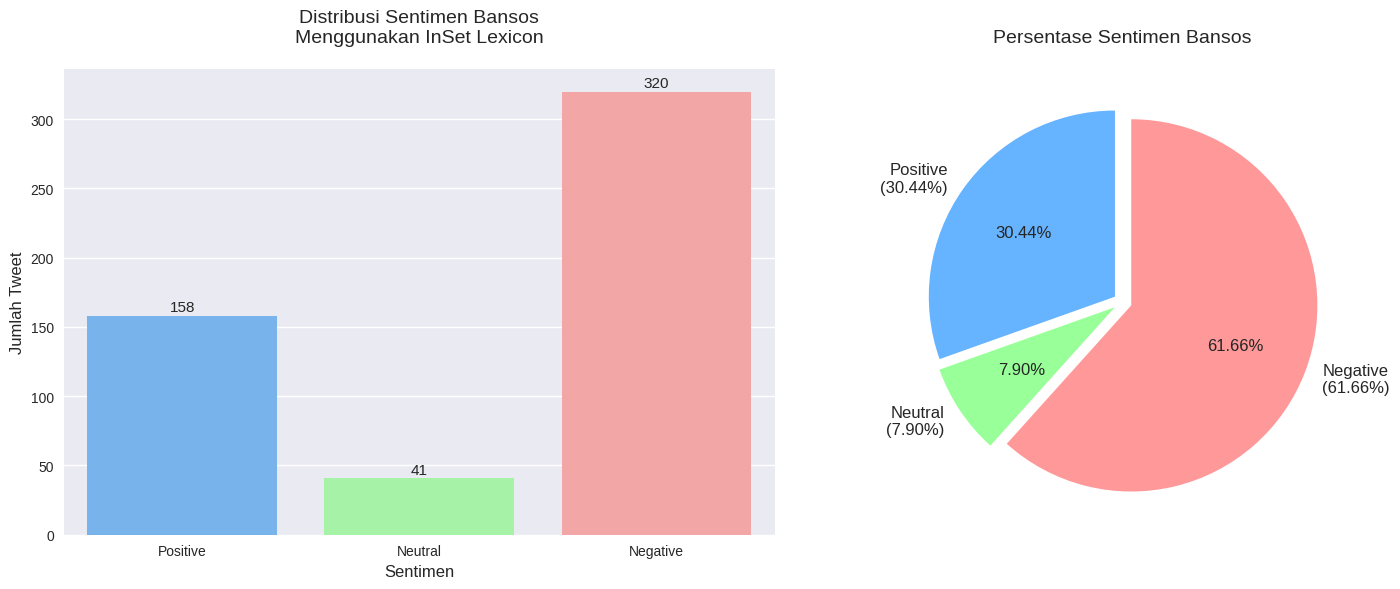

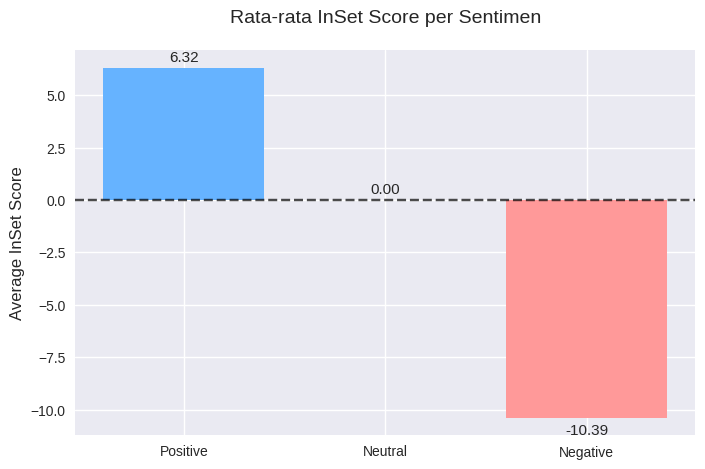

Visualisasi berhasil dibuat!


In [8]:
# ============================================================
# VISUALISASI DISTRIBUSI SENTIMEN INSET
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/bansos_inset_labeled_final.csv')

order = ['Positive', 'Neutral', 'Negative']
counts = df['inset_sentiment'].value_counts().reindex(order).fillna(0).astype(int)
percentages = (counts / counts.sum() * 100).round(2)

plt.style.use('seaborn-v0_8')
sns.set_palette("pastel")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ================== BAR CHART ==================
sns.barplot(
    x=counts.index,
    y=counts.values,
    ax=axes[0],
    palette=['#66b3ff', '#99ff99', '#ff9999']
)

axes[0].set_title('Distribusi Sentimen Bansos\nMenggunakan InSet Lexicon', fontsize=14, pad=20)
axes[0].set_xlabel('Sentimen', fontsize=12)
axes[0].set_ylabel('Jumlah Tweet', fontsize=12)

for i, value in enumerate(counts.values):
    axes[0].text(i, value + max(counts.values) * 0.01, str(value), ha='center', fontsize=11)

# ================== PIE CHART ==================
labels = [f"{sent}\n({percentages[sent]:.2f}%)" for sent in order if counts[sent] > 0]
sizes = [counts[sent] for sent in order if counts[sent] > 0]
colors = ['#66b3ff', '#99ff99', '#ff9999'][:len(sizes)]

axes[1].pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct='%1.2f%%',
    startangle=90,
    textprops={'fontsize': 12},
    explode=[0.05] * len(sizes)
)

axes[1].set_title('Persentase Sentimen Bansos', fontsize=14, pad=20)

plt.tight_layout()
plt.show()

# ================== AVERAGE SCORE CHART ==================
plt.figure(figsize=(8, 5))

avg_score = df.groupby('inset_sentiment')['inset_score'].mean().reindex(order)
bars = plt.bar(avg_score.index, avg_score.values, color=['#66b3ff', '#99ff99', '#ff9999'])

plt.title('Rata-rata InSet Score per Sentimen', fontsize=14, pad=20)
plt.ylabel('Average InSet Score', fontsize=12)
plt.axhline(y=0, color='black', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    if pd.notna(height):
        offset = 0.3 if height >= 0 else -0.8
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + offset,
            f'{height:.2f}',
            ha='center',
            fontsize=11
        )

plt.show()

print("Visualisasi berhasil dibuat!")


In [9]:
# ============================================================
# CEK HASIL LABELING INSET
# ============================================================
# Cell ini menggantikan perhitungan InSet lama agar tidak ada dua versi hasil sentimen.

df = pd.read_csv('/content/bansos_inset_labeled_final.csv')

print("Distribusi label English:")
print(df['inset_sentiment'].value_counts())

print("\nDistribusi label Indonesia untuk dashboard:")
print(df['sentiment_label'].value_counts())

df[['full_text', 'clean_text', 'inset_score', 'inset_sentiment', 'sentiment_label', 'matched_detail']].head(10)


Distribusi label English:
inset_sentiment
Negative    320
Positive    158
Neutral      41
Name: count, dtype: int64

Distribusi label Indonesia untuk dashboard:
sentiment_label
negatif    320
positif    158
netral      41
Name: count, dtype: int64


,full_text,clean_text,inset_score,inset_sentiment,sentiment_label,matched_detail
0,@Xbacottetangga Tdk kuasa kutahan airmata ini....,tidak kuasa kutahan airmata pemerintah lihat r...,-25.0,Negative,negatif,"tidak:-5, kuasa:3, lihat:3, walau:-3, cacat:-5..."
1,#DiskusiInteraktif Menunggu langkah tegas Peme...,diskusiinteraktif menunggu langkah tegas pemer...,1.0,Positive,positif,"menunggu:-3, langkah:4, perusahaan:3, seperti:..."
2,@embah72 Untung gw gak percaya program kaya gi...,untung gw tidak percaya program kaya gini bers...,-4.0,Negative,negatif,"untung:3, untung:-1, tidak:-5, percaya:2, kaya..."
3,@Anak__Ogi @DivHumas_Polri SDM rendah maklum s...,sdm rendah maklum saja rakyat bansos begitulah...,-22.0,Negative,negatif,"rendah:-5, maklum:3, maklum:-2, saja:-3, pola:..."
4,Nantikan Diskusi Interaktif Malam Ini: Menungg...,nantikan diskusi interaktif malam menunggu lan...,-4.0,Negative,negatif,"malam:-1, menunggu:-3, langkah:4, perusahaan:3..."
5,@UmarHasibuan__ Gk fair dong bicara hutang tdk...,tidak fair bicara hutang tidak bicara aset era...,-34.0,Negative,negatif,"tidak:-5, fair:3, hutang:-5, tidak:-5, meningg..."
6,Gk fair dong bicara hutang tdk bicara aset Era...,tidak fair bicara hutang tidak bicara aset era...,-34.0,Negative,negatif,"tidak:-5, fair:3, hutang:-5, tidak:-5, meningg..."
7,@fatkur_munir @NOTASLIMBOY Paan sih tiba-tiba ...,paan tiba tiba bansos hahaha tidak ada korelas...,-7.0,Negative,negatif,"tidak:-5, ada:4, ada:-3, naik:1, tinggal:1, ti..."
8,Nantikan Diskusi Interaktif Malam Ini: Menungg...,nantikan diskusi interaktif malam menunggu lan...,-4.0,Negative,negatif,"malam:-1, menunggu:-3, langkah:4, perusahaan:3..."
9,Gus Ipul Dukung Bansos untuk Warga Binaan Usul...,gus ipul dukung bansos warga binaan usul masuk...,0.0,Neutral,netral,"dukung:4, usul:2, usul:-3, masuk:-3"


In [10]:
# ============================================================
# RINGKASAN SENTIMEN UNTUK LAPORAN
# ============================================================

sentimen_summary = (
    df['sentiment_label']
    .value_counts()
    .rename_axis('Sentimen')
    .reset_index(name='Jumlah')
)

sentimen_summary['Persentase'] = (
    sentimen_summary['Jumlah'] / sentimen_summary['Jumlah'].sum() * 100
).round(2)

sentimen_summary


,Sentimen,Jumlah,Persentase
0,negatif,320,61.66
1,positif,158,30.44
2,netral,41,7.90


In [11]:
# ============================================================
# INSIGHT OTOMATIS HASIL SENTIMEN
# ============================================================

dominant = sentimen_summary.iloc[0]

print(
    f"Insight: Sentimen dominan adalah {dominant['Sentimen']} "
    f"dengan {dominant['Jumlah']} tweet ({dominant['Persentase']}%)."
)

if dominant['Sentimen'] == 'negatif':
    print("Artinya, percakapan publik tentang bansos cenderung berisi kritik, keluhan, atau ketidakpuasan.")
elif dominant['Sentimen'] == 'positif':
    print("Artinya, percakapan publik tentang bansos cenderung berisi dukungan atau respons baik.")
else:
    print("Artinya, sebagian besar tweet bersifat informatif atau tidak menunjukkan emosi yang kuat.")


Insight: Sentimen dominan adalah negatif dengan 320 tweet (61.66%).
Artinya, percakapan publik tentang bansos cenderung berisi kritik, keluhan, atau ketidakpuasan.


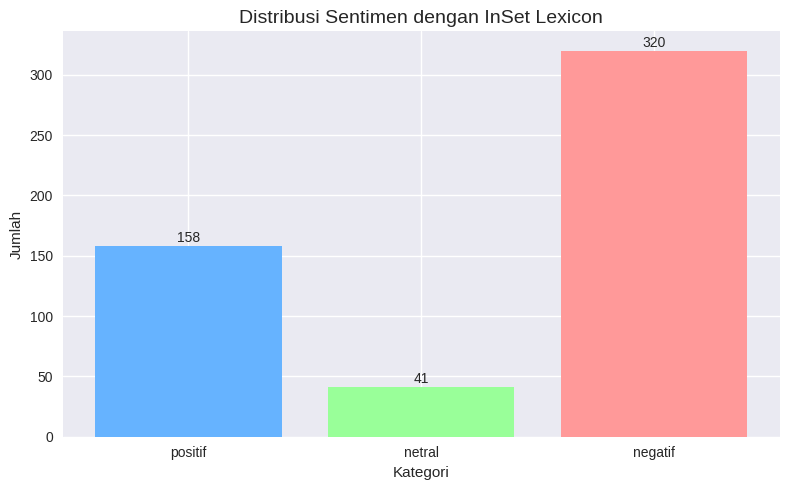

In [12]:
# ============================================================
# GRAFIK DISTRIBUSI SENTIMEN LABEL INDONESIA
# ============================================================

import matplotlib.pyplot as plt

plot_order = ['positif', 'netral', 'negatif']
plot_counts = df['sentiment_label'].value_counts().reindex(plot_order).fillna(0)

plt.figure(figsize=(8, 5))
bars = plt.bar(plot_counts.index, plot_counts.values, color=['#66b3ff', '#99ff99', '#ff9999'])

plt.title("Distribusi Sentimen dengan InSet Lexicon", fontsize=14)
plt.xlabel("Kategori")
plt.ylabel("Jumlah")
plt.xticks(rotation=0)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + max(plot_counts.values) * 0.01,
        int(height),
        ha='center'
    )

plt.tight_layout()
plt.show()


In [13]:
# Cell lama yang menghitung sentimen dengan rumus berbeda sudah dinonaktifkan.
# Gunakan kolom berikut sebagai sumber utama:
# - inset_score
# - inset_sentiment
# - sentiment_label


In [14]:
df[['full_text', 'clean_text', 'inset_score', 'inset_sentiment', 'sentiment_label']].head(10)


,full_text,clean_text,inset_score,inset_sentiment,sentiment_label
0,@Xbacottetangga Tdk kuasa kutahan airmata ini....,tidak kuasa kutahan airmata pemerintah lihat r...,-25.0,Negative,negatif
1,#DiskusiInteraktif Menunggu langkah tegas Peme...,diskusiinteraktif menunggu langkah tegas pemer...,1.0,Positive,positif
2,@embah72 Untung gw gak percaya program kaya gi...,untung gw tidak percaya program kaya gini bers...,-4.0,Negative,negatif
3,@Anak__Ogi @DivHumas_Polri SDM rendah maklum s...,sdm rendah maklum saja rakyat bansos begitulah...,-22.0,Negative,negatif
4,Nantikan Diskusi Interaktif Malam Ini: Menungg...,nantikan diskusi interaktif malam menunggu lan...,-4.0,Negative,negatif
5,@UmarHasibuan__ Gk fair dong bicara hutang tdk...,tidak fair bicara hutang tidak bicara aset era...,-34.0,Negative,negatif
6,Gk fair dong bicara hutang tdk bicara aset Era...,tidak fair bicara hutang tidak bicara aset era...,-34.0,Negative,negatif
7,@fatkur_munir @NOTASLIMBOY Paan sih tiba-tiba ...,paan tiba tiba bansos hahaha tidak ada korelas...,-7.0,Negative,negatif
8,Nantikan Diskusi Interaktif Malam Ini: Menungg...,nantikan diskusi interaktif malam menunggu lan...,-4.0,Negative,negatif
9,Gus Ipul Dukung Bansos untuk Warga Binaan Usul...,gus ipul dukung bansos warga binaan usul masuk...,0.0,Neutral,netral


In [15]:
sentimen_summary


,Sentimen,Jumlah,Persentase
0,negatif,320,61.66
1,positif,158,30.44
2,netral,41,7.90


In [16]:
# Grafik distribusi sentimen sudah dibuat pada cell sebelumnya.
# Jalankan ulang dari cell "LOAD & PERBAIKI KAMUS INSET" jika ingin memperbarui hasil.


# 2. Klasterisasi + Deteksi Trending Topic

In [17]:
# import library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
nltk.download("stopwords", quiet=True)

pd.set_option("display.max_colwidth", 150)

In [18]:
# ============================================================
# LOAD DATA UNTUK KLASTERISASI
# ============================================================
# Penting:
# Jika file hasil labeling InSet sudah ada, gunakan file tersebut agar
# kolom sentimen tetap terbawa sampai export dashboard.
# Ini mencegah dashboard membaca semua data sebagai netral.

from pathlib import Path
import pandas as pd

if Path('/content/bansos_inset_labeled_final.csv').exists():
    df = pd.read_csv('/content/bansos_inset_labeled_final.csv')
    print("Data yang digunakan: bansos_inset_labeled_final.csv")
else:
    df = pd.read_csv('/content/bansos.csv')
    print("Data yang digunakan: bansos.csv")

print("Jumlah data awal:", len(df))
print("Kolom:", df.columns.tolist())

df[["created_at", "full_text"]].head()


Data yang digunakan: bansos_inset_labeled_final.csv
Jumlah data awal: 519
Kolom: ['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'clean_text', 'tokens', 'token_count', 'inset_score', 'inset_sentiment', 'matched_words', 'matched_detail', 'sentiment_score', 'sentiment_label']


,created_at,full_text
0,Tue Mar 31 23:52:16 +0000 2026,@Xbacottetangga Tdk kuasa kutahan airmata ini. Utk Pemerintah lihat nih Rakyat Kecilmu walau kondisi fisiknya cacat namun ttp berjuang cari nafkah...
1,Tue Mar 31 17:05:00 +0000 2026,#DiskusiInteraktif Menunggu langkah tegas Pemerintah terhadap perusahaan teknologi global seperti Meta dan Google bila tidak patuhi aturan PP Tuna...
2,Tue Mar 31 15:17:31 +0000 2026,@embah72 Untung gw gak percaya program kaya gini Bersyukur ga punya mental ngemis ditambah gak pernah minat sama acara bagi bagi bansos begini
3,Tue Mar 31 14:57:30 +0000 2026,@Anak__Ogi @DivHumas_Polri SDM rendah maklum saja rakyat bansos ya begitulah pola pikirnya enga memikirkan kesehatan anaknya giliran anaknya sakit...
4,Tue Mar 31 14:46:18 +0000 2026,Nantikan Diskusi Interaktif Malam Ini: Menunggu langkah tegas Pemerintah terhadap perusahaan teknologi global seperti Meta dan Google bila tidak p...


In [19]:
#stopwords

stop_words_id = set(stopwords.words("indonesian"))

custom_stopwords = {
    "yg", "ya", "ga", "gak", "nggak", "nya", "sih", "kok", "deh", "aja",
    "kayak", "dgn", "utk", "dll", "krn", "sm", "tp", "jg", "dr", "sdh",
    "udah", "buat", "apa", "siapa", "kapan", "dimana", "kenapa", "gimana",
    "itu", "ini", "dan", "atau", "tapi", "karena", "jadi", "ada", "dari",
    "ke", "di", "yang", "dengan", "untuk", "pada", "adalah", "mereka",
    "kita", "aku", "kamu", "dia", "gw", "gue", "lu", "loe", "gua", "in",
    "bgt", "banget", "kalo", "shi", "ku", "bikin", "amp", "b", "yaa", "pengen",
    "tuh", "a", "an", "orang", "beneran", "with", "jin", "si", "kek",

    # tambahan khas dataset bansos di Twitter/X
    "rt", "nih", "dah", "ni", "tu", "klo", "gitu", "gini", "udh", "blm",
    "dpt", "jdi", "trus", "terus", "td", "tdk", "tak", "bs", "bisa", "mau",
}

all_stopwords = stop_words_id.union(custom_stopwords)
print("Total stopwords dipakai:", len(all_stopwords))

Total stopwords dipakai: 820


In [20]:
# preprocessing
def clean_text_proper(text):
    text = str(text).lower()
    # Hapus URL
    text = re.sub(r"http\S+|www\S+|https\S+", "", text, flags=re.MULTILINE)
    # Hapus mention dan hashtag
    text = re.sub(r"\@\w+|\#\w+", "", text)
    # Hapus tanda baca
    text = re.sub(r"[^\w\s]", "", text)
    # Hapus angka
    text = re.sub(r"\d+", "", text)

    words = text.split()
    filtered_words = [w for w in words if w not in all_stopwords and len(w) > 2]
    return " ".join(filtered_words)


df["clean_text"] = df["full_text"].apply(clean_text_proper)

# Buang baris yang hasil cleaning-nya kosong
before = len(df)
df = df[df["clean_text"].str.strip().astype(bool)].reset_index(drop=True)
after = len(df)
print(f"Jumlah data: {before} -> {after} (setelah membuang teks kosong)")

df[["full_text", "clean_text"]].head(5)

Jumlah data: 519 -> 516 (setelah membuang teks kosong)


,full_text,clean_text
0,@Xbacottetangga Tdk kuasa kutahan airmata ini. Utk Pemerintah lihat nih Rakyat Kecilmu walau kondisi fisiknya cacat namun ttp berjuang cari nafkah...,kuasa kutahan airmata pemerintah lihat rakyat kecilmu kondisi fisiknya cacat ttp berjuang cari nafkah tersentuh bantuan klian apbn ngr hny dibuang...
1,#DiskusiInteraktif Menunggu langkah tegas Pemerintah terhadap perusahaan teknologi global seperti Meta dan Google bila tidak patuhi aturan PP Tuna...,menunggu langkah pemerintah perusahaan teknologi global meta google patuhi aturan tunas larangan anak usia akun medsos talk praktisi hukum pusat b...
2,@embah72 Untung gw gak percaya program kaya gini Bersyukur ga punya mental ngemis ditambah gak pernah minat sama acara bagi bagi bansos begini,untung percaya program kaya bersyukur mental ngemis ditambah minat acara bansos
3,@Anak__Ogi @DivHumas_Polri SDM rendah maklum saja rakyat bansos ya begitulah pola pikirnya enga memikirkan kesehatan anaknya giliran anaknya sakit...,sdm rendah maklum rakyat bansos pola pikirnya enga memikirkan kesehatan anaknya giliran anaknya sakit teriak tolong kenceng tua tolol
4,Nantikan Diskusi Interaktif Malam Ini: Menunggu langkah tegas Pemerintah terhadap perusahaan teknologi global seperti Meta dan Google bila tidak p...,nantikan diskusi interaktif malam menunggu langkah pemerintah perusahaan teknologi global meta google patuhi aturan tunas larangan anak usia akun ...


In [21]:
# Cek hasil cleaning (Harusnya kata "yang", "ini", "itu" sudah hilang)
print("Contoh hasil cleaning:")
print(df[['full_text', 'clean_text']].head(3))
print("\n")

Contoh hasil cleaning:
                                                                                                                                               full_text  \
0  @Xbacottetangga Tdk kuasa kutahan airmata ini. Utk Pemerintah lihat nih Rakyat Kecilmu walau kondisi fisiknya cacat namun ttp berjuang cari nafkah...   
1  #DiskusiInteraktif Menunggu langkah tegas Pemerintah terhadap perusahaan teknologi global seperti Meta dan Google bila tidak patuhi aturan PP Tuna...   
2         @embah72 Untung gw gak percaya program kaya gini Bersyukur ga punya mental ngemis ditambah gak pernah minat sama acara bagi bagi bansos begini   

                                                                                                                                              clean_text  
0  kuasa kutahan airmata pemerintah lihat rakyat kecilmu kondisi fisiknya cacat ttp berjuang cari nafkah tersentuh bantuan klian apbn ngr hny dibuang...  
1  menunggu langkah pemerintah perusahaan 

In [22]:
# Ekstraksi Fitur (TF-IDF) dan Reduksi Dimensi (SVD)
vectorizer = TfidfVectorizer(max_features=1000, min_df=2)
X_tfidf = vectorizer.fit_transform(df["clean_text"])
print("Ukuran matriks TF-IDF:", X_tfidf.shape)

svd = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd.fit_transform(X_tfidf)
print("Total variansi yang terjelaskan oleh 2 komponen SVD: {:.2%}".format(svd.explained_variance_ratio_.sum()))

Ukuran matriks TF-IDF: (516, 1000)
Total variansi yang terjelaskan oleh 2 komponen SVD: 3.89%


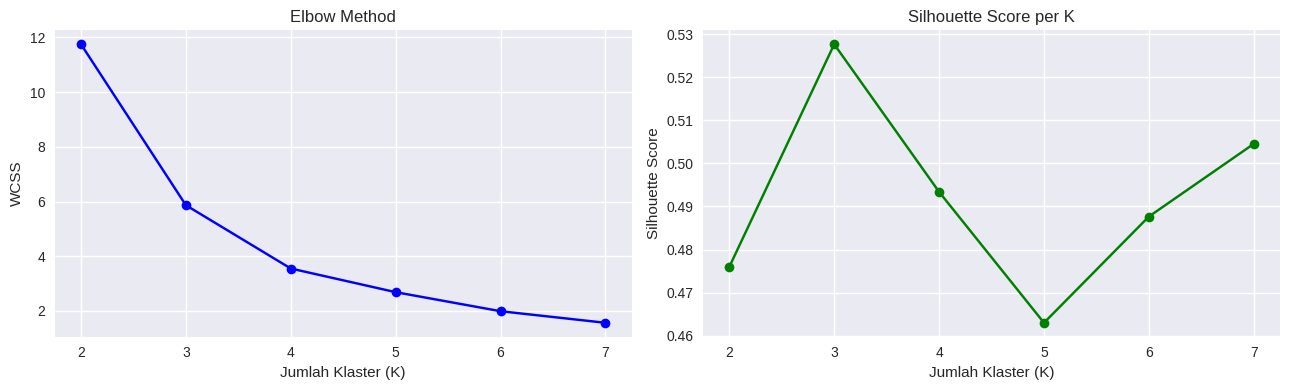

K=2 -> Silhouette Score: 0.4760
K=3 -> Silhouette Score: 0.5276
K=4 -> Silhouette Score: 0.4934
K=5 -> Silhouette Score: 0.4630
K=6 -> Silhouette Score: 0.4876
K=7 -> Silhouette Score: 0.5045


In [23]:
# menentukan jumlah klaster optimal

wcss = []
sil_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_2d)
    wcss.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_2d, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(list(K_range), wcss, "bo-")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Jumlah Klaster (K)")
axes[0].set_ylabel("WCSS")

axes[1].plot(list(K_range), sil_scores, "go-")
axes[1].set_title("Silhouette Score per K")
axes[1].set_xlabel("Jumlah Klaster (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

for k, s in zip(K_range, sil_scores):
    print(f"K={k} -> Silhouette Score: {s:.4f}")

cluster
0    154
1    353
2      9
Name: count, dtype: int64


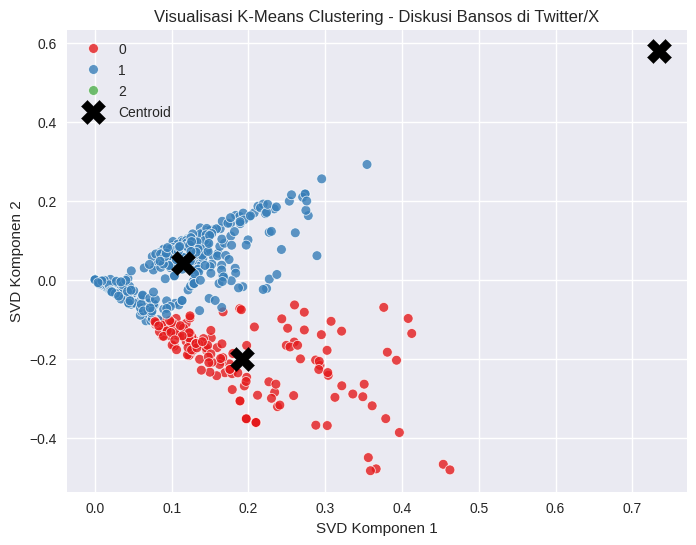

In [24]:
# K-Means clustering final

optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["cluster"] = kmeans_final.fit_predict(X_2d)

print(df["cluster"].value_counts().sort_index())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=df["cluster"], palette="Set1", s=50, alpha=0.8)
plt.scatter(
    kmeans_final.cluster_centers_[:, 0],
    kmeans_final.cluster_centers_[:, 1],
    s=300, c="black", marker="X", label="Centroid"
)
plt.title("Visualisasi K-Means Clustering - Diskusi Bansos di Twitter/X")
plt.xlabel("SVD Komponen 1")
plt.ylabel("SVD Komponen 2")
plt.legend()
plt.show()

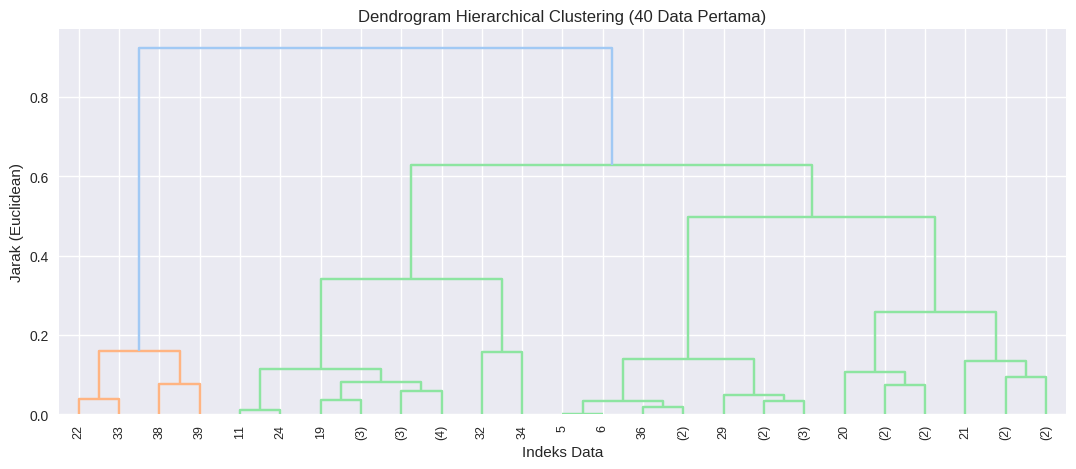

In [25]:
# hierarchical clustering

X_dendro = X_2d[:40]

plt.figure(figsize=(13, 5))
dendrogram(
    linkage(X_dendro, method="ward"),
    truncate_mode="level", p=5,
    leaf_rotation=90.0,
    leaf_font_size=9.0,
)
plt.title("Dendrogram Hierarchical Clustering (40 Data Pertama)")
plt.xlabel("Indeks Data")
plt.ylabel("Jarak (Euclidean)")
plt.show()

In [26]:
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    calinski_harabasz_score
)
# Hitung semua metrik evaluasi
sil = silhouette_score(X_2d, df['cluster'])
dbi = davies_bouldin_score(X_2d, df['cluster'])
chi = calinski_harabasz_score(X_2d, df['cluster'])
print("=== Evaluasi K-Means ===")
print(f"Silhouette Score : {sil:.4f} (baik jika > 0.5)")
print(f"Davies-Bouldin Index: {dbi:.4f} (baik jika < 1.0)")
print(f"Calinski-Harabasz : {chi:.2f} (semakin besar semakin baik)")
# Interpretasi klaster — lihat tweet representatif tiap klaster

=== Evaluasi K-Means ===
Silhouette Score : 0.5276 (baik jika > 0.5)
Davies-Bouldin Index: 0.5455 (baik jika < 1.0)
Calinski-Harabasz : 586.78 (semakin besar semakin baik)


In [27]:
# ============================================================
# INTERPRETASI DAN PEMBERIAN LABEL 3 KLASTER K-MEANS
# ============================================================
# K-Means pada project ini menggunakan optimal_k = 3.
# Agar dashboard juga menampilkan 3 klaster, setiap angka cluster
# harus memiliki nama cluster_label yang berbeda.
#
# Catatan:
# - cluster ID 0/1/2 dapat berubah jika data/preprocessing berubah.
# - Jika hasil top kata berbeda, nama label boleh disesuaikan,
#   tetapi pastikan 3 cluster tetap memiliki 3 label yang berbeda.

from collections import Counter

print("RINGKASAN ISI TIAP CLUSTER")
print("=" * 80)

for c in sorted(df["cluster"].unique()):
    sub = df[df["cluster"] == c]
    words = Counter(
        w for t in sub["clean_text"].fillna("")
        for w in str(t).split()
        if len(w) > 3
    )

    print(f"\n=== Cluster {c} (n={len(sub)}) ===")
    print("Top kata:", [w for w, _ in words.most_common(12)])
    print("Contoh tweet:")
    for t in sub["full_text"].head(3):
        print(" -", str(t)[:140])

# ============================================================
# LABEL FINAL 3 KLASTER
# ============================================================
# Perbaikan utama:
# Sebelumnya cluster 0 dan cluster 2 sama-sama diberi label
# "Opini dan Keluhan Publik", sehingga dashboard menggabungkan
# keduanya dan hanya menampilkan 2 klaster.
# Sekarang setiap cluster diberi label unik agar dashboard menampilkan 3 klaster.

cluster_label_map = {
    0: "Opini dan Keluhan Publik",
    1: "Diskusi/Kebijakan Resmi Bansos",
    2: "Data tidak relevan/ noise",
}

# Terapkan label. Jika ada cluster lain di luar mapping, beri nama otomatis.
df["cluster_label"] = df["cluster"].apply(
    lambda x: cluster_label_map.get(int(x), f"Klaster {int(x)}")
)

print("\nVALIDASI LABEL KLASTER")
print("=" * 80)
print("Jumlah berdasarkan angka cluster:")
print(df["cluster"].value_counts().sort_index())

print("\nJumlah berdasarkan cluster_label:")
print(df["cluster_label"].value_counts())

print("\nCrosstab cluster vs cluster_label:")
print(pd.crosstab(df["cluster"], df["cluster_label"]))

jumlah_cluster = df["cluster"].nunique()
jumlah_label = df["cluster_label"].nunique()

print(f"\nJumlah cluster K-Means : {jumlah_cluster}")
print(f"Jumlah label dashboard : {jumlah_label}")

if jumlah_label < jumlah_cluster:
    print("PERINGATAN: Ada label yang masih sama sehingga cluster bisa tergabung di dashboard.")
else:
    print("OK: Dashboard akan menampilkan 3 klaster K-Means secara terpisah.")

df[["full_text", "cluster", "cluster_label"]].head(10)



RINGKASAN ISI TIAP CLUSTER

=== Cluster 0 (n=154) ===
Top kata: ['bantuan', 'pemerintah', 'sosial', 'program', 'bansos', 'warga', 'masyarakat', 'penyaluran', 'keluarga', 'indonesia', 'kementerian', 'pangan']
Contoh tweet:
 - @Xbacottetangga Tdk kuasa kutahan airmata ini. Utk Pemerintah lihat nih Rakyat Kecilmu walau kondisi fisiknya cacat namun ttp berjuang cari 
 - #DiskusiInteraktif Menunggu langkah tegas Pemerintah terhadap perusahaan teknologi global seperti Meta dan Google bila tidak patuhi aturan P
 - Pemerintah Indonesia menerapkan Data Tunggal Sosial Ekonomi Nasional (DTSEN) sebagai acuan utama penyaluran Kartu Indonesia Pintar (KIP) Kul

=== Cluster 1 (n=353) ===
Top kata: ['bansos', 'rakyat', 'dapet', 'negara', 'pemerintah', 'indonesia', 'sylus', 'prabowo', 'biar', 'miskin', 'masyarakat', 'presiden']
Contoh tweet:
 - @embah72 Untung gw gak percaya program kaya gini Bersyukur ga punya mental ngemis ditambah gak pernah minat sama acara bagi bagi bansos begi
 - @Anak__Ogi @DivHu

,full_text,cluster,cluster_label
0,@Xbacottetangga Tdk kuasa kutahan airmata ini. Utk Pemerintah lihat nih Rakyat Kecilmu walau kondisi fisiknya cacat namun ttp berjuang cari nafkah...,0,Opini dan Keluhan Publik
1,#DiskusiInteraktif Menunggu langkah tegas Pemerintah terhadap perusahaan teknologi global seperti Meta dan Google bila tidak patuhi aturan PP Tuna...,0,Opini dan Keluhan Publik
2,@embah72 Untung gw gak percaya program kaya gini Bersyukur ga punya mental ngemis ditambah gak pernah minat sama acara bagi bagi bansos begini,1,Diskusi/Kebijakan Resmi Bansos
3,@Anak__Ogi @DivHumas_Polri SDM rendah maklum saja rakyat bansos ya begitulah pola pikirnya enga memikirkan kesehatan anaknya giliran anaknya sakit...,1,Diskusi/Kebijakan Resmi Bansos
4,Nantikan Diskusi Interaktif Malam Ini: Menunggu langkah tegas Pemerintah terhadap perusahaan teknologi global seperti Meta dan Google bila tidak p...,1,Diskusi/Kebijakan Resmi Bansos
5,@UmarHasibuan__ Gk fair dong bicara hutang tdk bicara aset Era Pak Jokowi 2 periode meninggalkan aset negara Rp13.072 triliun sementara hutang sek...,1,Diskusi/Kebijakan Resmi Bansos
6,Gk fair dong bicara hutang tdk bicara aset Era Pak Jokowi 2 periode meninggalkan aset negara Rp13.072 triliun sementara hutang sekitar Rp5.392 tri...,1,Diskusi/Kebijakan Resmi Bansos
7,@fatkur_munir @NOTASLIMBOY Paan sih tiba-tiba bansos hahaha gak ada korelasinya. Nih ya BBM naik itu udah tinggal nunggu waktu. Emang kalo gak din...,1,Diskusi/Kebijakan Resmi Bansos
8,Nantikan Diskusi Interaktif Malam Ini: Menunggu langkah tegas Pemerintah terhadap perusahaan teknologi global seperti Meta dan Google bila tidak p...,1,Diskusi/Kebijakan Resmi Bansos
9,Gus Ipul Dukung Bansos untuk Warga Binaan Usul Masuk Skema PBI https://t.co/n9RxeiiLBo,1,Diskusi/Kebijakan Resmi Bansos


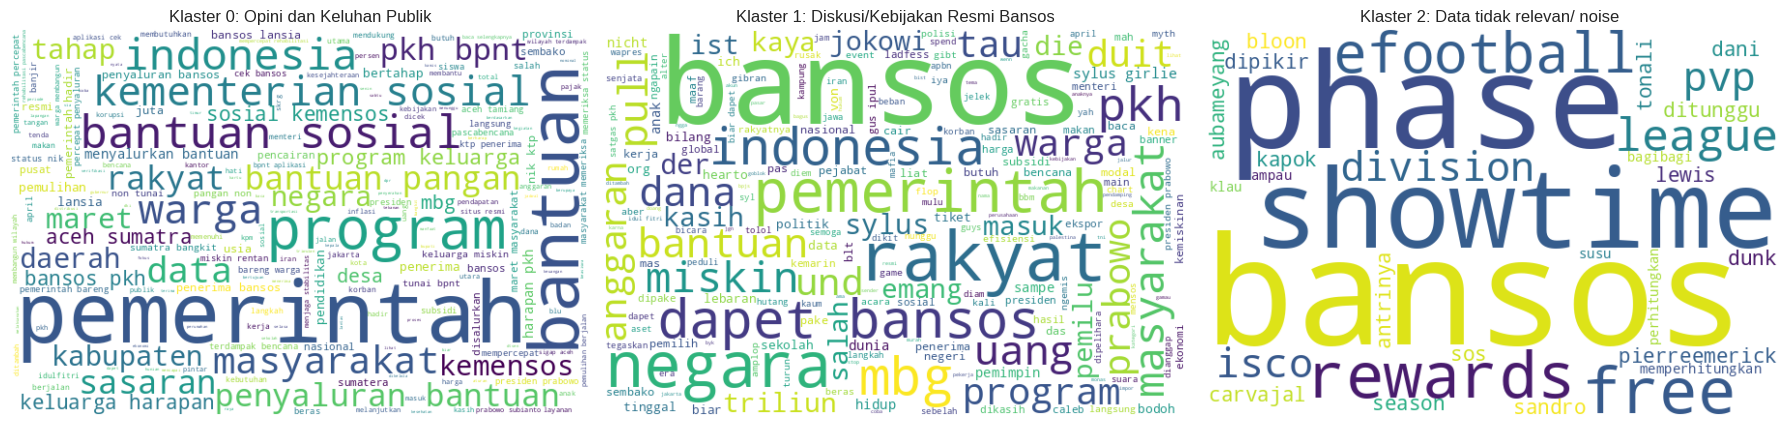

In [28]:
import os

# word cloud

n_clusters_plot = df["cluster"].nunique()
fig, axes = plt.subplots(1, n_clusters_plot, figsize=(6 * n_clusters_plot, 5))

if n_clusters_plot == 1:
    axes = [axes]

for ax, cluster_id in zip(axes, sorted(df["cluster"].unique())):
    text_gabungan = " ".join(df[df["cluster"] == cluster_id]["clean_text"])
    wc = WordCloud(width=600, height=400, background_color="white", colormap="viridis").generate(text_gabungan)
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    label = cluster_label_map.get(cluster_id, f"Klaster {cluster_id}")
    ax.set_title(f"Klaster {cluster_id}: {label}")

plt.tight_layout()

os.makedirs('klaster', exist_ok=True)
plt.savefig("klaster/wordcloud_per_klaster.png", dpi=150, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1790/2682417879.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=trending_df, x="Frekuensi", y="Kata", palette="rocket")


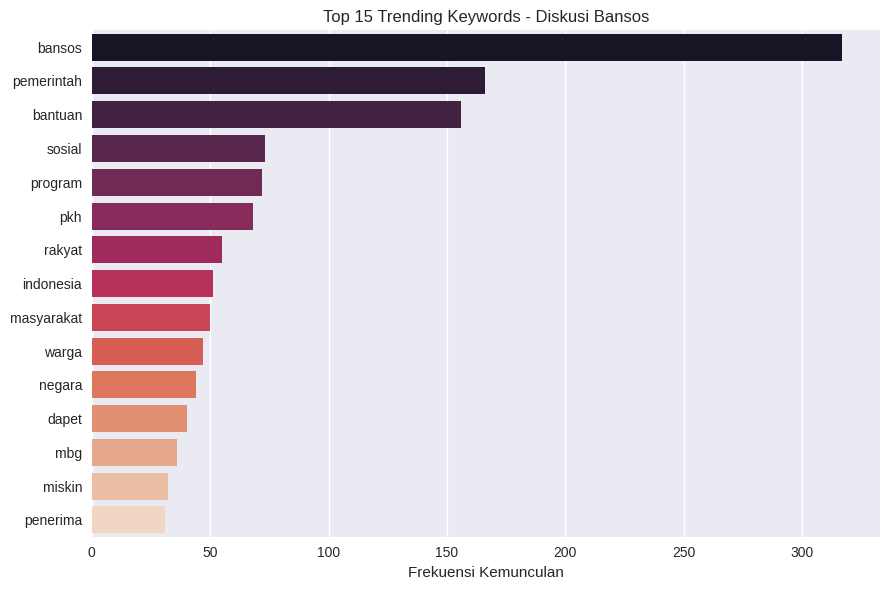

,Kata,Frekuensi
0,bansos,317
1,pemerintah,166
2,bantuan,156
3,sosial,73
4,program,72
5,pkh,68
6,rakyat,55
7,indonesia,51
8,masyarakat,50
9,warga,47


In [29]:
# trending keywords keseluruhan bansos
all_words = " ".join(df["clean_text"]).split()
word_freq = Counter(all_words)
top_n = 15
trending_keywords = word_freq.most_common(top_n)

trending_df = pd.DataFrame(trending_keywords, columns=["Kata", "Frekuensi"])

plt.figure(figsize=(9, 6))
sns.barplot(data=trending_df, x="Frekuensi", y="Kata", palette="rocket")
plt.title(f"Top {top_n} Trending Keywords - Diskusi Bansos")
plt.xlabel("Frekuensi Kemunculan")
plt.ylabel("")
plt.tight_layout()
plt.show()

trending_df

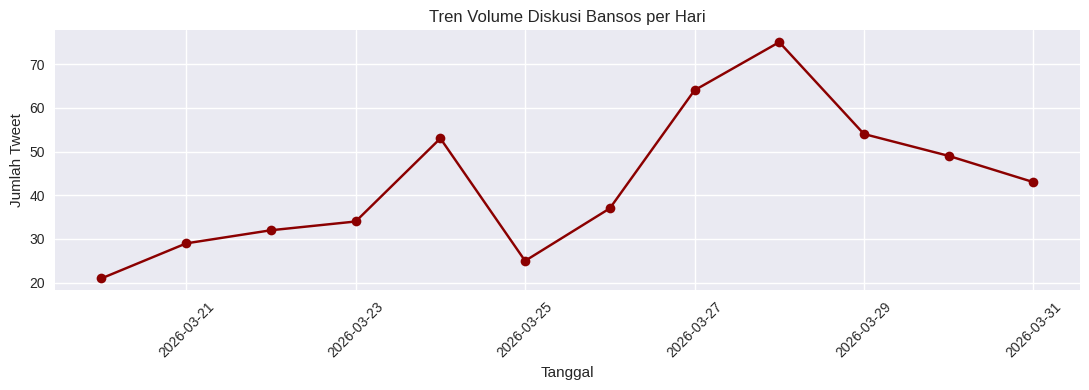

volume tertinggi terjadi pada tanggal 2026-03-28 
dengan 75 tweet.




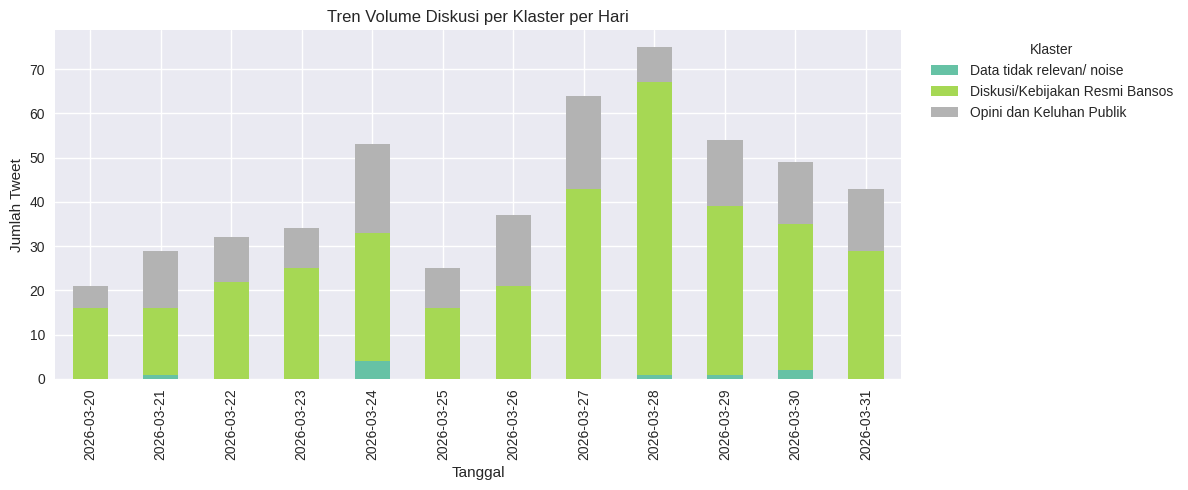

cluster_label,Data tidak relevan/ noise,Diskusi/Kebijakan Resmi Bansos,Opini dan Keluhan Publik
tanggal,,,
2026-03-20,0.0,16.0,5.0
2026-03-21,1.0,15.0,13.0
2026-03-22,0.0,22.0,10.0
2026-03-23,0.0,25.0,9.0
2026-03-24,4.0,29.0,20.0
2026-03-25,0.0,16.0,9.0
2026-03-26,0.0,21.0,16.0
2026-03-27,0.0,43.0,21.0
2026-03-28,1.0,66.0,8.0


In [30]:
# TREN VOLUME

# tren volume diskusi per hari
df["created_at_parsed"] = pd.to_datetime(
    df["created_at"], format="%a %b %d %H:%M:%S %z %Y", errors="coerce"
)
df["tanggal"] = df["created_at_parsed"].dt.date

volume_harian = df.groupby("tanggal").size().reset_index(name="jumlah_tweet")

plt.figure(figsize=(11, 4))
plt.plot(volume_harian["tanggal"], volume_harian["jumlah_tweet"], marker="o", color="darkred")
plt.title("Tren Volume Diskusi Bansos per Hari")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Tweet")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

puncak = volume_harian.loc[volume_harian["jumlah_tweet"].idxmax()]
print(f"volume tertinggi terjadi pada tanggal {puncak['tanggal']} \ndengan {puncak['jumlah_tweet']} tweet.")

print("\n")
# tren volume per klaster per hari
volume_per_klaster = (
    df.groupby(["tanggal", "cluster_label"]).size().reset_index(name="jumlah_tweet")
)
pivot_klaster = volume_per_klaster.pivot(index="tanggal", columns="cluster_label", values="jumlah_tweet").fillna(0)

pivot_klaster.plot(kind="bar", stacked=True, figsize=(12, 5), colormap="Set2")
plt.title("Tren Volume Diskusi per Klaster per Hari")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Tweet")
plt.legend(title="Klaster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

pivot_klaster

In [31]:
# ============================================================
# EXPORT HASIL KLASTERISASI UNTUK DASHBOARD — FINAL FIX
# ============================================================
# Tujuan perbaikan:
# 1. Distribusi sentimen di dashboard harus sama dengan Colab.
# 2. Data utama untuk dashboard memakai bansos_inset_labeled_final.csv.
# 3. Hasil clustering ditempelkan ke data InSet.
# 4. Jika ada tweet yang tidak masuk clustering karena clean_text kosong,
#    tweet tersebut tetap masuk dashboard dengan cluster = -1.
#
# Dengan cara ini, jumlah data dashboard tetap 519 dan distribusi sentimen
# tidak berkurang menjadi 516.

import os
import json
import pandas as pd
import numpy as np
from pathlib import Path

os.makedirs("klaster", exist_ok=True)

# ============================================================
# 1. PAKAI DATA INSET SEBAGAI DATA UTAMA DASHBOARD
# ============================================================
if Path("/content/bansos_inset_labeled_final.csv").exists():
    df_inset_full = pd.read_csv("/content/bansos_inset_labeled_final.csv")
    print("Data utama dashboard: bansos_inset_labeled_final.csv")
else:
    # fallback jika file InSet belum dibuat
    df_inset_full = df.copy()
    print("PERINGATAN: bansos_inset_labeled_final.csv belum ditemukan. Menggunakan df aktif.")

# Samakan tipe id agar proses merge tidak gagal
if "id_str" in df_inset_full.columns:
    df_inset_full["id_str"] = df_inset_full["id_str"].astype(str)

if "id_str" in df.columns:
    df["id_str"] = df["id_str"].astype(str)

# ============================================================
# 2. NORMALISASI SENTIMEN INSET
# ============================================================
def normalisasi_sentimen_dashboard(x):
    x = str(x).strip().lower()
    if x in ["positive", "positif", "pos"]:
        return "positif"
    elif x in ["negative", "negatif", "neg"]:
        return "negatif"
    elif x in ["neutral", "netral", "neu"]:
        return "netral"
    return "netral"

if "inset_score" in df_inset_full.columns:
    df_inset_full["inset_score"] = pd.to_numeric(df_inset_full["inset_score"], errors="coerce").fillna(0)
    df_inset_full["sentiment_score"] = df_inset_full["inset_score"]
elif "sentiment_score" not in df_inset_full.columns:
    df_inset_full["sentiment_score"] = 0

if "inset_sentiment" in df_inset_full.columns:
    df_inset_full["sentiment_label"] = df_inset_full["inset_sentiment"].apply(normalisasi_sentimen_dashboard)
elif "sentiment_label" in df_inset_full.columns:
    df_inset_full["sentiment_label"] = df_inset_full["sentiment_label"].apply(normalisasi_sentimen_dashboard)
else:
    df_inset_full["sentiment_label"] = "netral"

# ============================================================
# 3. TEMPELKAN HASIL CLUSTERING KE DATA UTAMA
# ============================================================
cluster_cols = [c for c in ["id_str", "full_text", "cluster", "cluster_label", "tanggal"] if c in df.columns]
cluster_result = df[cluster_cols].copy()

# Buang kolom cluster lama dari data utama agar tidak bentrok
for col in ["cluster", "cluster_label", "tanggal"]:
    if col in df_inset_full.columns:
        df_inset_full = df_inset_full.drop(columns=[col])

if "cluster" in cluster_result.columns:
    if "id_str" in df_inset_full.columns and "id_str" in cluster_result.columns:
        cluster_result = cluster_result.drop_duplicates("id_str")
        df_dashboard = df_inset_full.merge(cluster_result, on="id_str", how="left")
    elif "full_text" in df_inset_full.columns and "full_text" in cluster_result.columns:
        cluster_result = cluster_result.drop_duplicates("full_text")
        df_dashboard = df_inset_full.merge(cluster_result, on="full_text", how="left")
    else:
        df_dashboard = df_inset_full.copy()
else:
    df_dashboard = df_inset_full.copy()

# ============================================================
# 4. TWEET YANG TIDAK MASUK CLUSTER TETAP DIMASUKKAN DASHBOARD
# ============================================================
if "cluster" not in df_dashboard.columns:
    df_dashboard["cluster"] = -1

if "cluster_label" not in df_dashboard.columns:
    df_dashboard["cluster_label"] = "Tidak Masuk Klaster"

missing_cluster_count = df_dashboard["cluster"].isna().sum()

df_dashboard["cluster"] = df_dashboard["cluster"].fillna(-1).astype(int)
df_dashboard["cluster_label"] = df_dashboard["cluster_label"].fillna("Tidak Masuk Klaster")

# ============================================================
# 4B. PERBAIKAN LABEL KLASTER AGAR DASHBOARD MENAMPILKAN 3 KLASTER
# ============================================================
# Dashboard mengelompokkan data berdasarkan cluster_label.
# Jika dua angka cluster memiliki nama label yang sama, dashboard akan terlihat hanya 2 klaster.
# Karena itu, paksa setiap cluster K-Means valid mengikuti cluster_label_map yang unik.
cluster_label_map_dashboard = globals().get("cluster_label_map", {
    0: "Opini dan Keluhan Publik",
    1: "Diskusi/Kebijakan Resmi Bansos",
    2: "Informasi Program dan Penerima Bansos",
})

valid_cluster_mask = df_dashboard["cluster"].isin(list(cluster_label_map_dashboard.keys()))
df_dashboard.loc[valid_cluster_mask, "cluster_label"] = df_dashboard.loc[valid_cluster_mask, "cluster"].map(cluster_label_map_dashboard)
df_dashboard.loc[df_dashboard["cluster"].eq(-1), "cluster_label"] = "Tidak Masuk Klaster"

# ============================================================
# 5. BUAT KOLOM TANGGAL JIKA BELUM ADA
# ============================================================
if "tanggal" not in df_dashboard.columns or df_dashboard["tanggal"].isna().all():
    if "created_at" in df_dashboard.columns:
        created_at_parsed = pd.to_datetime(df_dashboard["created_at"], errors="coerce")
        df_dashboard["tanggal"] = created_at_parsed.dt.date.astype(str)
    else:
        df_dashboard["tanggal"] = ""
else:
    df_dashboard["tanggal"] = df_dashboard["tanggal"].astype(str)

# ============================================================
# 6. PASTIKAN KOLOM PENTING ADA
# ============================================================
for col in ["favorite_count", "retweet_count", "reply_count", "quote_count"]:
    if col not in df_dashboard.columns:
        df_dashboard[col] = 0
    df_dashboard[col] = pd.to_numeric(df_dashboard[col], errors="coerce").fillna(0)

for col in ["in_reply_to_screen_name", "user_id_str", "username"]:
    if col not in df_dashboard.columns:
        df_dashboard[col] = ""

# Jika username kosong, pakai user_id_str agar SNA/dashboard tetap jalan
if "username" in df_dashboard.columns and "user_id_str" in df_dashboard.columns:
    kosong_username = df_dashboard["username"].isna() | (df_dashboard["username"].astype(str).str.strip() == "")
    df_dashboard.loc[kosong_username, "username"] = "user_" + df_dashboard.loc[kosong_username, "user_id_str"].astype(str)

# ============================================================
# 7. EXPORT FILE DASHBOARD
# ============================================================
kolom_export = [
    "id_str", "created_at", "tanggal", "full_text", "clean_text",
    "cluster", "cluster_label", "sentiment_score", "sentiment_label",
    "inset_score", "inset_sentiment", "matched_words", "matched_detail",
    "favorite_count", "retweet_count", "reply_count", "quote_count",
    "in_reply_to_screen_name", "user_id_str", "username", "tweet_url"
]

kolom_export = [c for c in kolom_export if c in df_dashboard.columns]

df_export = df_dashboard[kolom_export].copy()
df_export.to_csv("klaster/hasil_klasterisasi_bansos.csv", index=False)

# ============================================================
# 8. EXPORT METRICS CLUSTERING
# ============================================================
cluster_sizes = {}
if "cluster" in df.columns:
    cluster_sizes = {str(k): int(v) for k, v in df["cluster"].value_counts().sort_index().items()}

metrics_klaster = {
    "optimal_k": int(optimal_k) if "optimal_k" in globals() else None,
    "silhouette": float(sil) if "sil" in globals() else None,
    "davies_bouldin": float(dbi) if "dbi" in globals() else None,
    "calinski_harabasz": float(chi) if "chi" in globals() else None,
    "k_range": list(K_range) if "K_range" in globals() else None,
    "silhouette_per_k": [float(x) for x in sil_scores] if "sil_scores" in globals() else None,
    "wcss_per_k": [float(x) for x in wcss] if "wcss" in globals() else None,
    "cluster_sizes": cluster_sizes,
    "cluster_label_counts": {str(k): int(v) for k, v in df_dashboard["cluster_label"].value_counts().items()} if "cluster_label" in df_dashboard.columns else {},
    "jumlah_label_klaster_dashboard": int(df_dashboard.loc[df_dashboard["cluster"].ne(-1), "cluster_label"].nunique()) if "cluster_label" in df_dashboard.columns else None,
    "cluster_sizes": cluster_sizes,
    "jumlah_data_inset": int(len(df_inset_full)),
    "jumlah_data_cluster": int(len(df)) if "df" in globals() else None,
    "jumlah_data_dashboard": int(len(df_export)),
    "tweet_tidak_masuk_cluster": int(missing_cluster_count)
}

with open("klaster/metrics_klaster.json", "w", encoding="utf-8") as f:
    json.dump(metrics_klaster, f, ensure_ascii=False, indent=2)

# ============================================================
# 9. VALIDASI HASIL
# ============================================================
print("\nDistribusi sentimen dari file InSet:")
print(df_inset_full["sentiment_label"].value_counts().reindex(["positif", "netral", "negatif"]).fillna(0).astype(int))

print("\nDistribusi sentimen yang masuk dashboard:")
print(df_export["sentiment_label"].value_counts().reindex(["positif", "netral", "negatif"]).fillna(0).astype(int))

print("\nRingkasan jumlah data:")
print("- Jumlah data InSet      :", len(df_inset_full))
print("- Jumlah data clustering :", len(df))
print("- Jumlah data dashboard  :", len(df_export))
print("- Tidak masuk clustering :", missing_cluster_count)


print("\nValidasi klaster untuk dashboard:")
print("Jumlah berdasarkan cluster:")
print(df_export["cluster"].value_counts().sort_index())
print("\nJumlah berdasarkan cluster_label:")
print(df_export["cluster_label"].value_counts())
print("\nCrosstab cluster vs cluster_label:")
print(pd.crosstab(df_export["cluster"], df_export["cluster_label"]))

jumlah_label_utama = df_export.loc[df_export["cluster"].ne(-1), "cluster_label"].nunique()
print("\nJumlah label klaster utama di dashboard:", jumlah_label_utama)
if jumlah_label_utama == 3:
    print("OK: Dashboard akan menampilkan 3 klaster utama sesuai optimal_k = 3.")
else:
    print("PERINGATAN: Dashboard belum menampilkan 3 klaster utama. Cek cluster_label_map.")

print("\nFile dashboard berhasil dibuat:")
print("- klaster/hasil_klasterisasi_bansos.csv")
print("- klaster/metrics_klaster.json")

df_export.head()





Data utama dashboard: bansos_inset_labeled_final.csv

Distribusi sentimen dari file InSet:
sentiment_label
positif    158
netral      41
negatif    320
Name: count, dtype: int64

Distribusi sentimen yang masuk dashboard:
sentiment_label
positif    158
netral      41
negatif    320
Name: count, dtype: int64

Ringkasan jumlah data:
- Jumlah data InSet      : 519
- Jumlah data clustering : 516
- Jumlah data dashboard  : 519
- Tidak masuk clustering : 3

Validasi klaster untuk dashboard:
Jumlah berdasarkan cluster:
cluster
-1      3
 0    154
 1    353
 2      9
Name: count, dtype: int64

Jumlah berdasarkan cluster_label:
cluster_label
Diskusi/Kebijakan Resmi Bansos    353
Opini dan Keluhan Publik          154
Data tidak relevan/ noise           9
Tidak Masuk Klaster                 3
Name: count, dtype: int64

Crosstab cluster vs cluster_label:


/tmp/ipykernel_1790/1330545853.py:146: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['user_1688663918099812353' 'user_121640063' 'user_1841844252441276416'
 'user_1933697176506626048' 'user_121640063' 'user_1759100655783043072'
 'user_1759100655783043072' 'user_232746593' 'user_121640063'
 'user_150589950' 'user_118371948' 'user_1216362687828856832'
 'user_48359478' 'user_1590845630037229569' 'user_1604064608913723394'
 'user_1221589522359545856' 'user_1845514131509739520'
 'user_1981555039820001280' 'user_716658315871191040'
 'user_1996595044997070848' 'user_71436318' 'user_71436318'
 'user_255866913' 'user_1493854642908057601' 'user_1963262807711137792'
 'user_1244819229578121216' 'user_21861624' 'user_1565985151246802945'
 'user_1520253067748585472' 'user_2889531644' 'user_1451692249918570497'
 'user_1905189562248527872' 'user_228571961' 'user_57261519'
 'user_154435354' 'user_2889531644' 'user_10179

cluster_label  Data tidak relevan/ noise  Diskusi/Kebijakan Resmi Bansos  \
cluster                                                                    
-1                                     0                               0   
 0                                     0                               0   
 1                                     0                             353   
 2                                     9                               0   

cluster_label  Opini dan Keluhan Publik  Tidak Masuk Klaster  
cluster                                                       
-1                                    0                    3  
 0                                  154                    0  
 1                                    0                    0  
 2                                    0                    0  

Jumlah label klaster utama di dashboard: 3
OK: Dashboard akan menampilkan 3 klaster utama sesuai optimal_k = 3.

File dashboard berhasil dibuat:
- klaster/hasil_kla

,id_str,created_at,tanggal,clean_text,cluster,cluster_label,sentiment_score,sentiment_label,inset_score,inset_sentiment,matched_words,matched_detail,favorite_count,retweet_count,reply_count,quote_count,in_reply_to_screen_name,user_id_str,username,tweet_url
0,2039128676667957437,Tue Mar 31 23:52:16 +0000 2026,2026-03-31,tidak kuasa kutahan airmata pemerintah lihat rakyat kecilmu walau kondisi fisiknya cacat namun tetap berjuang cari nafkah tidak tersentuh bantuan ...,0,Opini dan Keluhan Publik,-25.0,negatif,-25.0,Negative,14,"tidak:-5, kuasa:3, lihat:3, walau:-3, cacat:-5, tetap:3, cari:-3, nafkah:3, tidak:-5, tersentuh:-2, hanya:-3, dibuang:-3, sia:-5, pejabat:-3",25,2,1,0,Xbacottetangga,1688663918099812353,user_1688663918099812353,https://x.com/undefined/status/2039128676667957437
1,2039026185112314153,Tue Mar 31 17:05:00 +0000 2026,2026-03-31,diskusiinteraktif menunggu langkah tegas pemerintah terhadap perusahaan teknologi global seperti meta google bila tidak patuhi aturan pp tunas ten...,0,Opini dan Keluhan Publik,1.0,positif,1.0,Positive,16,"menunggu:-3, langkah:4, perusahaan:3, seperti:-1, tidak:-5, tunas:3, tunas:-2, tentang:1, tentang:-2, anak:-3, punya:3, hukum:3, hukum:-3, pusat:3...",0,0,0,0,NaN,121640063,user_121640063,https://x.com/undefined/status/2039026185112314153
2,2038999134582259955,Tue Mar 31 15:17:31 +0000 2026,2026-03-31,untung gw tidak percaya program kaya gini bersyukur tidak punya mental ngemis ditambah tidak pernah minat acara bagi bagi bansos begini,1,Diskusi/Kebijakan Resmi Bansos,-4.0,negatif,-4.0,Negative,16,"untung:3, untung:-1, tidak:-5, percaya:2, kaya:2, kaya:-2, bersyukur:5, tidak:-5, punya:3, tidak:-5, minat:4, bagi:2, bagi:-4, bagi:2, bagi:-4, be...",5,1,0,0,embah72,1841844252441276416,user_1841844252441276416,https://x.com/undefined/status/2038999134582259955
3,2038994099483951369,Tue Mar 31 14:57:30 +0000 2026,2026-03-31,sdm rendah maklum saja rakyat bansos begitulah pola pikirnya enga memikirkan kesehatan anaknya giliran anaknya sakit baru teriak minta tolong nya ...,1,Diskusi/Kebijakan Resmi Bansos,-22.0,negatif,-22.0,Negative,16,"rendah:-5, maklum:3, maklum:-2, saja:-3, pola:3, memikirkan:-3, giliran:3, sakit:-5, teriak:-2, minta:2, minta:-3, tolong:3, tolong:-2, kenceng:-2...",2,1,0,0,Anak__Ogi,1933697176506626048,user_1933697176506626048,https://x.com/undefined/status/2038994099483951369
4,2038991280072769922,Tue Mar 31 14:46:18 +0000 2026,2026-03-31,nantikan diskusi interaktif malam menunggu langkah tegas pemerintah terhadap perusahaan teknologi global seperti meta google bila tidak patuhi atu...,1,Diskusi/Kebijakan Resmi Bansos,-4.0,negatif,-4.0,Negative,14,"malam:-1, menunggu:-3, langkah:4, perusahaan:3, seperti:-1, tidak:-5, tunas:3, tunas:-2, tentang:1, tentang:-2, anak:-3, punya:3, komunitas:2, kom...",1,1,0,0,NaN,121640063,user_121640063,https://x.com/undefined/status/2038991280072769922


### 3. Social Network Analysis (SNA)
Bagian ini fokus pada pemetaan hubungan antar pengguna di media sosial Twitter/X terkait topik Bansos.

In [32]:
import networkx as nx
import matplotlib.pyplot as plt

# Memfilter data yang memiliki interaksi (reply)
sna_df = df[df['in_reply_to_screen_name'].notnull()].copy()

# Karena kolom 'username' di dataset awal banyak yang kosong (NaN),
# kita akan menggunakan 'user_id_str' sebagai pengganti sementara untuk node pengirim,
# atau jika ada kolom username yang valid bisa digunakan.
# Mari kita coba buat edge list: (pengirim) -> (penerima/reply_to)

# Catatan: Di dataset ini 'username' kosong, kita gunakan 'user_id_str' sebagai representasi user
sna_df['source'] = sna_df['user_id_str'].astype(str)
sna_df['target'] = sna_df['in_reply_to_screen_name']

# Membuat objek graph
G = nx.from_pandas_edgelist(sna_df, source='source', target='target', create_using=nx.DiGraph())

print(f"Jumlah Node (Aktor): {G.number_of_nodes()}")
print(f"Jumlah Edges (Interaksi): {G.number_of_edges()}")

Jumlah Node (Aktor): 395
Jumlah Edges (Interaksi): 222


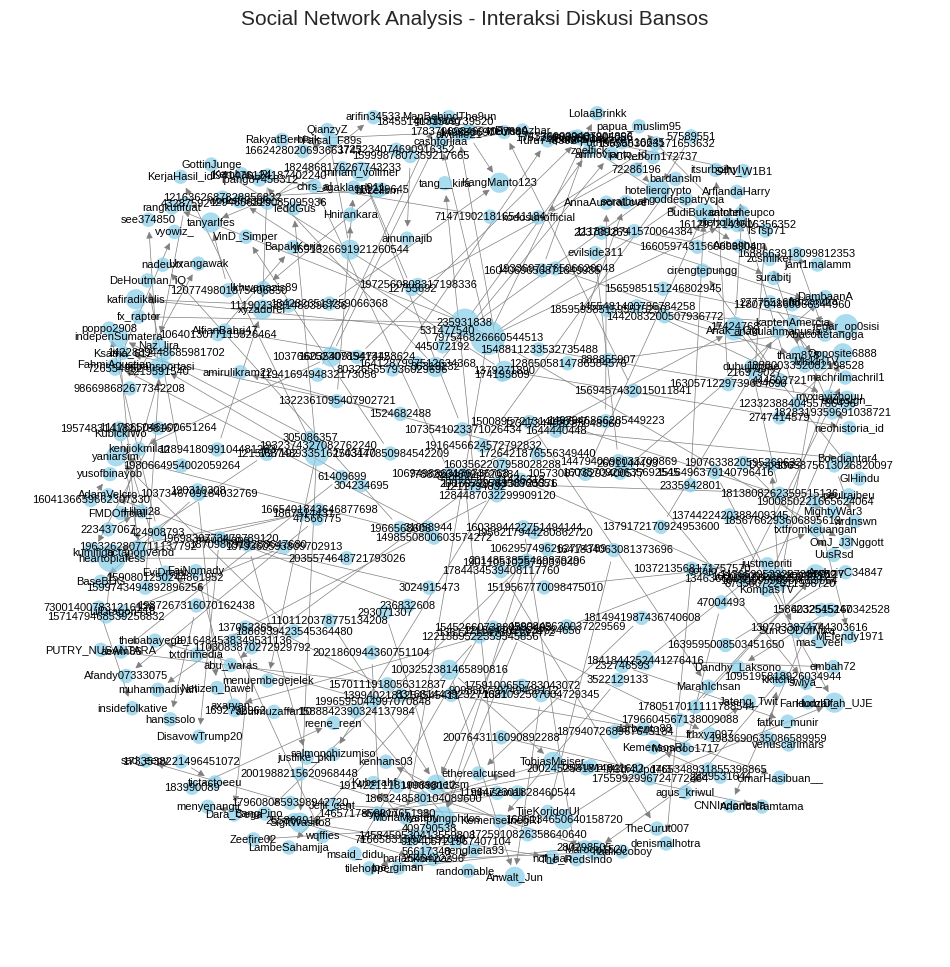

In [33]:
# Visualisasi Jaringan SNA sederhana
plt.figure(figsize=(12, 12))

# Menghitung derajat (degree) untuk ukuran node
degrees = dict(G.degree())
node_sizes = [v * 100 for v in degrees.values()]

pos = nx.spring_layout(G, k=0.15, iterations=20)

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='skyblue', alpha=0.7)
nx.draw_networkx_edges(G, pos, width=0.5, edge_color='grey', arrows=True)
nx.draw_networkx_labels(G, pos, font_size=8, font_family='sans-serif')

plt.title("Social Network Analysis - Interaksi Diskusi Bansos", fontsize=15)
plt.axis('off')
plt.show()

In [34]:
# Menghitung Centrality (Aktor Paling Berpengaruh)
print("=== Top 10 User Berdasarkan Degree Centrality ===")
centrality = nx.degree_centrality(G)
top_centrality = sorted(centrality.items(), key=lambda x: x[1], reverse=True)[:10]

for i, (node, score) in enumerate(top_centrality, 1):
    print(f"{i}. {node}: {score:.4f}")

=== Top 10 User Berdasarkan Degree Centrality ===
1. 797546826660544513: 0.0152
2. heartopiafess: 0.0102
3. 235931838: 0.0102
4. regar_op0sisi: 0.0076
5. kampungphilos: 0.0076
6. hoteliercrypto: 0.0076
7. 1637489335162503170: 0.0076
8. 1841844252441276416: 0.0051
9. Anak__Ogi: 0.0051
10. indepenSumatera: 0.0051


### 3.1. Analisis Metrik Sentralitas Lanjutan (Sesuai Modul)
Berdasarkan referensi SNA, kita akan menghitung beberapa metrik sentralitas untuk menentukan aktor mana yang paling krusial dalam menyebarkan informasi bansos.

In [35]:
import pandas as pd
import networkx as nx

# Menghitung berbagai metrik sentralitas
betweenness = nx.betweenness_centrality(G)
closeness = nx.closeness_centrality(G)
eigenvector = nx.eigenvector_centrality(G, max_iter=1000)

# Menggabungkan ke dalam DataFrame untuk perbandingan
centrality_df = pd.DataFrame({
    'User': list(centrality.keys()),
    'Degree': list(centrality.values()),
    'Betweenness': [betweenness[node] for node in centrality.keys()],
    'Closeness': [closeness[node] for node in centrality.keys()],
    'Eigenvector': [eigenvector[node] for node in centrality.keys()]
})

# Menampilkan 10 besar aktor paling berpengaruh (Bridge/Perantara)
print("Top 10 Aktor Berdasarkan Betweenness Centrality (Penyambung Informasi):")
display(centrality_df.sort_values(by='Betweenness', ascending=False).head(10))

Top 10 Aktor Berdasarkan Betweenness Centrality (Penyambung Informasi):


,User,Degree,Betweenness,Closeness,Eigenvector
394,venuscarimars,0.002538,0.0,0.002538,0.058197
0,1688663918099812353,0.002538,0.0,0.000000,0.000295
1,Xbacottetangga,0.002538,0.0,0.002538,0.058197
2,1841844252441276416,0.005076,0.0,0.000000,0.000295
3,embah72,0.002538,0.0,0.002538,0.058197
4,1933697176506626048,0.002538,0.0,0.000000,0.000295
5,Anak__Ogi,0.005076,0.0,0.005076,0.116099
6,1759100655783043072,0.002538,0.0,0.000000,0.000295
7,UmarHasibuan__,0.002538,0.0,0.002538,0.058197
8,232746593,0.002538,0.0,0.000000,0.000295


### 3.2. Deteksi Komunitas (Community Detection)
Untuk melihat apakah ada pengelompokan (kubu) dalam diskusi bansos ini, kita bisa menggunakan algoritma *Louvain* atau *Girvan-Newman*.

Ditemukan 174 komunitas besar dalam jaringan ini.


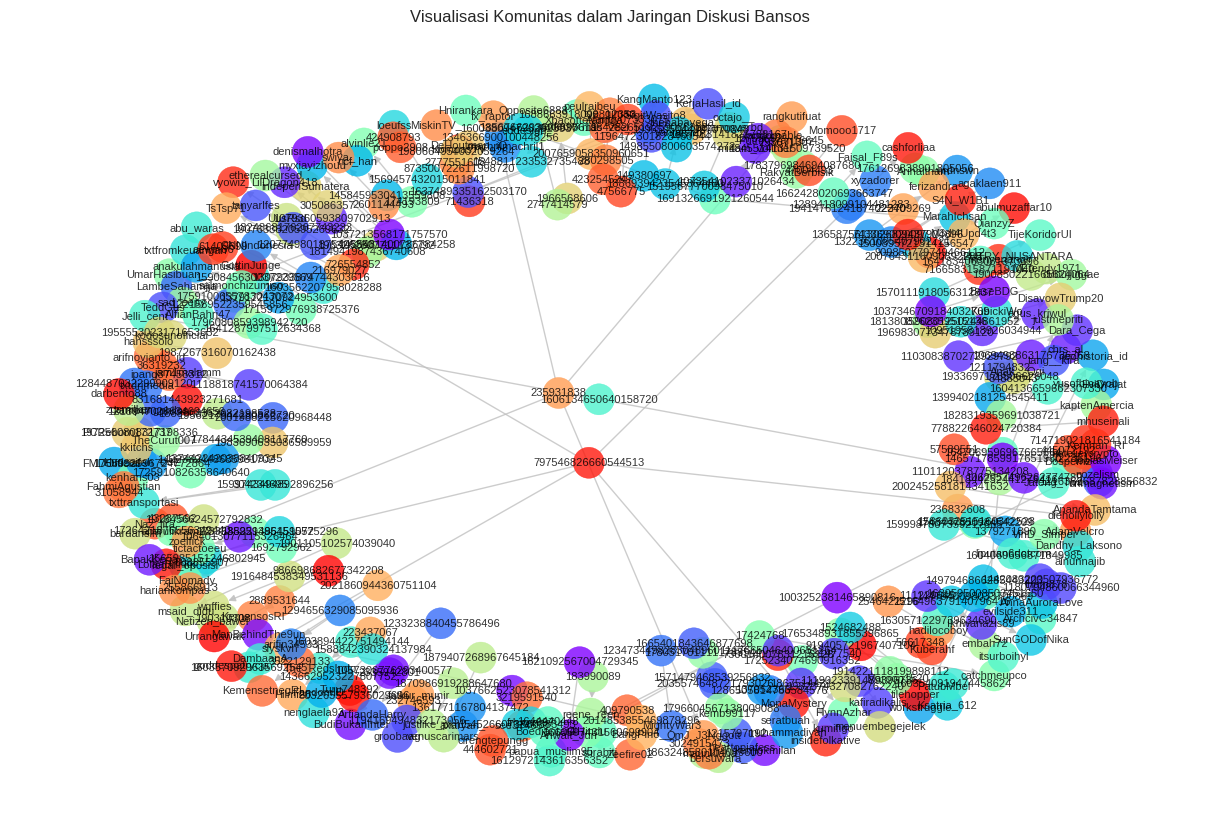

In [36]:
from networkx.algorithms import community

# Menggunakan Girvan-Newman untuk mendeteksi komunitas (cluster interaksi)
communities_generator = community.girvan_newman(G.to_undirected())
top_level_communities = next(communities_generator)
communities = sorted(map(sorted, top_level_communities))

print(f"Ditemukan {len(communities)} komunitas besar dalam jaringan ini.")

# Memberikan warna berbeda untuk setiap komunitas pada visualisasi
color_map = []
for node in G:
    for i, comm in enumerate(communities):
        if node in comm:
            color_map.append(i)
            break
    else:
        color_map.append(0)

plt.figure(figsize=(12, 8))
nx.draw_spring(G, node_color=color_map, with_labels=True, node_size=500,
               cmap=plt.cm.rainbow, font_size=8, edge_color='silver', alpha=0.8)
plt.title("Visualisasi Komunitas dalam Jaringan Diskusi Bansos")
plt.show()

# 4. Pembuatan Dashboard (Streamlit)
Bagian ini akan membuat file `app.py` yang bisa dijalankan sebagai dashboard interaktif.

In [37]:
!pkill -f streamlit || true
!pkill -f localtunnel || true

^C
^C


In [38]:
!pip install streamlit -q
!npm install -g localtunnel -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 58.6 MB/s eta 0:00:00
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋
added 22 packages in 2s
⠋
⠋3 packages are looking for funding
⠋  run `npm fund` for details
⠋

dashboard


In [39]:
# ============================================================
# FIX RUN DASHBOARD STREAMLIT DI GOOGLE COLAB
# Jalankan cell ini setelah:
# 1) File app.py sudah dibuat
# 2) File data sudah ada: /content/klaster/hasil_klasterisasi_bansos.csv
#    atau /content/bansos.csv
# ============================================================

!pip -q install streamlit plotly scikit-learn pandas numpy

import os, re, time, subprocess, textwrap
from pathlib import Path

# Pastikan posisi kerja di /content
%cd /content

# Matikan proses lama agar URL tunnel tidak nyangkut ke server mati
!pkill -f streamlit || true
!pkill -f cloudflared || true

# Validasi file penting
if not Path("app.py").exists():
    raise FileNotFoundError("app.py belum ada. Jalankan cell %%writefile app.py terlebih dahulu atau upload app.py ke /content.")

has_processed = Path("klaster/hasil_klasterisasi_bansos.csv").exists()
has_raw = Path("bansos.csv").exists()
if not (has_processed or has_raw):
    raise FileNotFoundError(
        "Data belum ditemukan. Letakkan salah satu: "
        "/content/klaster/hasil_klasterisasi_bansos.csv atau /content/bansos.csv"
    )

# Download cloudflared
if not Path("cloudflared").exists():
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
    !chmod +x cloudflared

# Jalankan Streamlit di background
streamlit_log = open("streamlit.log", "w")
streamlit_proc = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
    ],
    stdout=streamlit_log,
    stderr=subprocess.STDOUT,
)

time.sleep(8)

# Kalau Streamlit mati, tampilkan penyebabnya
if streamlit_proc.poll() is not None:
    print("STREAMLIT GAGAL JALAN. Isi streamlit.log:")
    print(Path("streamlit.log").read_text(errors="ignore")[-4000:])
    raise SystemExit("Perbaiki error Streamlit di atas, lalu jalankan ulang cell ini.")

# Tes server lokal
print("Cek server lokal:")
!curl -I http://localhost:8501 2>/dev/null | head -n 5 || true

# Jalankan Cloudflare Tunnel
cloud_log = open("cloudflared.log", "w")
cloud_proc = subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
    stdout=cloud_log,
    stderr=subprocess.STDOUT,
)

time.sleep(10)

log_text = Path("cloudflared.log").read_text(errors="ignore")
urls = re.findall(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", log_text)

if urls:
    print("\nDashboard berhasil dibuat. Buka URL ini:")
    print(urls[-1])
else:
    print("URL Cloudflare belum muncul. Isi cloudflared.log:")
    print(log_text[-4000:])


/content
^C
^C
Cek server lokal:
HTTP/1.1 200 OK
date: Sun, 05 Jul 2026 04:03:45 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes

Dashboard berhasil dibuat. Buka URL ini:
https://much-homeland-examination-bluetooth.trycloudflare.com


In [40]:
# ============================================================
# AUTO RUN DASHBOARD STREAMLIT + CLOUDFLARE
# Jalankan Run All, link dashboard akan otomatis muncul di output cell ini.
# Catatan: tampilan dashboard tetap berada di file app.py / app_final_kmeans_explanation.py
# ============================================================

import os
import re
import time
import subprocess
from pathlib import Path
from IPython.display import display, HTML

# 1) Install library dashboard jika belum ada
subprocess.run("pip -q install streamlit plotly pandas numpy", shell=True)

# 2) Pilih file dashboard yang akan dijalankan
candidates = [
    "app_final_kmeans_explanation.py",
    "app.py"
]

app_file = None
for fname in candidates:
    p = Path(fname)
    if p.exists():
        try:
            content = p.read_text(encoding="utf-8", errors="ignore")
        except Exception:
            content = ""
        # Prioritaskan app yang sudah ada penjelasan K-Means
        if "Penjelasan Evaluasi K-Means" in content or fname == "app_final_kmeans_explanation.py":
            app_file = fname
            break

if app_file is None:
    for fname in candidates:
        if Path(fname).exists():
            app_file = fname
            break

if app_file is None:
    raise FileNotFoundError(
        "File dashboard tidak ditemukan. Upload salah satu file: app_final_kmeans_explanation.py atau app.py"
    )

print(f"File dashboard yang dijalankan: {app_file}")

# 3) Install/download cloudflared jika belum ada
cloudflared_path = Path("cloudflared")
if not cloudflared_path.exists():
    print("Mengunduh cloudflared...")
    subprocess.run(
        "wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared",
        shell=True,
        check=True
    )
    subprocess.run("chmod +x cloudflared", shell=True)
else:
    subprocess.run("chmod +x cloudflared", shell=True)

# 4) Matikan proses lama agar link tidak bentrok
subprocess.run("pkill -f 'streamlit run' || true", shell=True)
subprocess.run("pkill -f 'cloudflared tunnel' || true", shell=True)
time.sleep(2)

# 5) Jalankan Streamlit
port = 8501
Path("streamlit.log").write_text("", encoding="utf-8")
Path("cloudflared.log").write_text("", encoding="utf-8")

streamlit_cmd = f"streamlit run {app_file} --server.port {port} --server.address 0.0.0.0 > streamlit.log 2>&1 &"
subprocess.run(streamlit_cmd, shell=True)

time.sleep(5)

# 6) Jalankan Cloudflare Tunnel
cloudflared_cmd = f"./cloudflared tunnel --url http://localhost:{port} > cloudflared.log 2>&1 &"
subprocess.run(cloudflared_cmd, shell=True)

# 7) Ambil URL trycloudflare otomatis
url = None
pattern = r"https://[-a-zA-Z0-9]+\.trycloudflare\.com"

print("Menunggu link dashboard...")
for _ in range(60):
    time.sleep(1)
    log_text = ""
    if Path("cloudflared.log").exists():
        log_text = Path("cloudflared.log").read_text(encoding="utf-8", errors="ignore")
    match = re.search(pattern, log_text)
    if match:
        url = match.group(0)
        break

if url:
    print("Dashboard berhasil dibuat. Buka URL ini:")
    print(url)
    html = f"""
    <div style='padding:16px;border:1px solid #ff7a30;border-radius:10px;background:#111;color:white;font-family:Arial;'>
        <h3 style='margin:0 0 8px 0;color:#ff7a30;'>Dashboard Streamlit Siap Dibuka</h3>
        <p style='margin:0 0 12px 0;'>Klik tombol di bawah untuk membuka dashboard.</p>
        <a href='{url}' target='_blank' style='background:#ff5a00;color:white;padding:10px 16px;border-radius:8px;text-decoration:none;font-weight:bold;display:inline-block;'>Buka Dashboard</a>
    </div>
    """
    display(HTML(html))
else:
    print("Link Cloudflare belum muncul. Cek log berikut:")
    print("\n===== cloudflared.log =====")
    print(Path("cloudflared.log").read_text(encoding="utf-8", errors="ignore")[-3000:])
    print("\n===== streamlit.log =====")
    print(Path("streamlit.log").read_text(encoding="utf-8", errors="ignore")[-3000:])


File dashboard yang dijalankan: app.py
Menunggu link dashboard...
Dashboard berhasil dibuat. Buka URL ini:
https://jade-rev-opportunities-guild.trycloudflare.com
